In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, f1_score
from transformers import AutoTokenizer, AutoModelForSequenceClassification

In [ ]:
DATA_PATH = "../data/processed/jigsaw_clean.parquet"
PROBES_PATH = "../data/probe_sentences.csv"
MAIN_IDENTITIES = [
    "male", "female", "homosexual_gay_or_lesbian", "christian", "jewish",
    "muslim", "black", "white", "psychiatric_or_mental_illness",
]

In [ ]:
MODELS = {
    "base lr 2e-5": "full_lr2e-05_ep4",
    "base lr 3e-5": "full_lr3e-05_ep4",
    "soft labels": "soft_lr2e-05_ep2",
    "soft labels + identity weights": "soft_idw_lr2e-05_ep2",
}

# 1. Training Metrics

In [33]:
cols = {"epoch": "Epoch", "train_loss": "Train loss", "eval_loss": "Val loss",
        "eval_auc": "Val AUC", "eval_pr_auc": "Val PR-AUC", "eval_recall": "Val recall", "eval_f1": "Val F1"}

for name, run in MODELS.items():
    # Mean training loss of each epoch, from the loss logged every 200 steps
    log = pd.read_csv(f"../results/metrics/{run}/train_log.csv")
    log = log[log["loss"].notna()]
    train_loss = log.groupby(np.ceil(log["epoch"]).astype(int))["loss"].mean().rename("train_loss")

    table = pd.read_csv(f"../results/metrics/{run}/epochs.csv")
    table["epoch"] = table["epoch"].astype(int)
    table = table.join(train_loss, on="epoch")[list(cols)].rename(columns=cols)

    print(f"\n{name}")
    display(table.round(3).set_index("Epoch"))




base lr 2e-5


,Train loss,Val loss,Val AUC,Val PR-AUC,Val recall,Val F1
Epoch,,,,,,
1,0.149,0.142,0.957,0.754,0.666,0.679
2,0.124,0.143,0.959,0.767,0.529,0.645
3,0.108,0.154,0.958,0.762,0.641,0.678
4,0.090,0.196,0.953,0.751,0.619,0.670



base lr 3e-5


,Train loss,Val loss,Val AUC,Val PR-AUC,Val recall,Val F1
Epoch,,,,,,
1,0.156,0.148,0.948,0.729,0.574,0.648
2,0.147,0.167,0.946,0.736,0.475,0.603
3,0.132,0.151,0.949,0.744,0.644,0.668
4,0.119,0.159,0.952,0.745,0.592,0.657



soft labels


,Train loss,Val loss,Val AUC,Val PR-AUC,Val recall,Val F1
Epoch,,,,,,
1,0.239,0.233,0.964,0.783,0.628,0.687
2,0.225,0.232,0.966,0.790,0.586,0.679



soft labels + identity weights


,Train loss,Val loss,Val AUC,Val PR-AUC,Val recall,Val F1
Epoch,,,,,,
1,0.257,0.250,0.964,0.781,0.613,0.682
2,0.243,0.249,0.965,0.788,0.590,0.679


# 2. Confusion Matrix

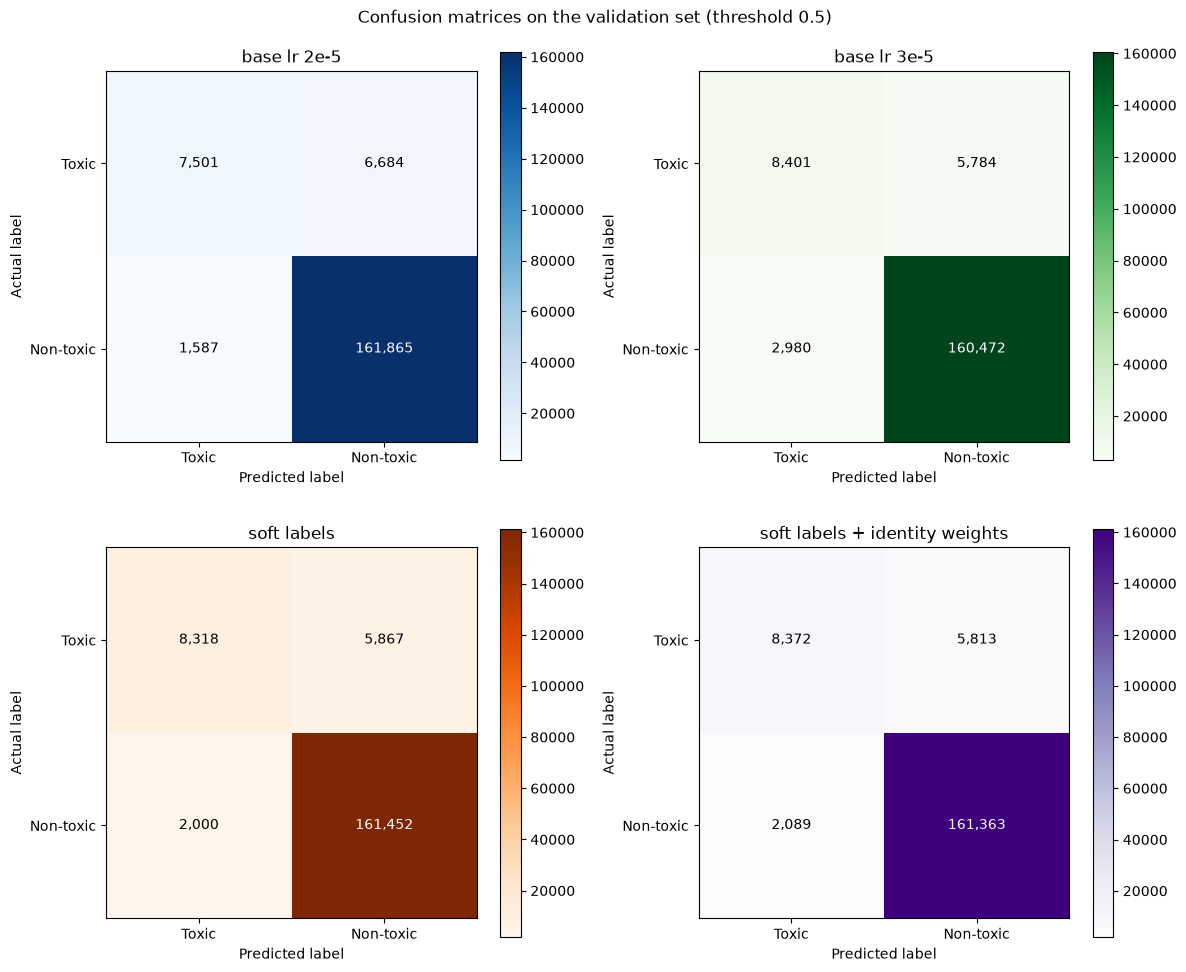

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
cmaps = ["Blues", "Greens", "Oranges", "Purples"]
order = [1, 0]  # toxic first

for ax, cmap, (name, p) in zip(axes.ravel(), cmaps, preds.items()):
    counts = pd.crosstab(p["label"], p["pred"]).reindex(index=order, columns=order, fill_value=0)
    im = ax.imshow(counts, cmap=cmap)
    fig.colorbar(im, ax=ax)
    for (i, j), n in np.ndenumerate(counts.values):
        ax.text(j, i, f"{n:,}", ha="center", va="center", color="white" if n > counts.values.max() / 2 else "black")
    ax.set_xticks([0, 1], ["Toxic", "Non-toxic"])
    ax.set_yticks([0, 1], ["Toxic", "Non-toxic"])
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
    ax.set_title(name)

fig.suptitle("Confusion matrices on the validation set (threshold 0.5)")
plt.tight_layout()
plt.show()

In [34]:
summary = {}
for name, p in preds.items():
    summary[name] = {
        "AUC": roc_auc_score(p["label"], p["prob_toxic"]),
        "PR-AUC": average_precision_score(p["label"], p["prob_toxic"]),
        "Precision": precision_score(p["label"], p["pred"]),
        "Recall": recall_score(p["label"], p["pred"]),
        "F1": f1_score(p["label"], p["pred"]),
    }
pd.DataFrame(summary).T.round(3)


,AUC,PR-AUC,Precision,Recall,F1
base lr 2e-5,0.959,0.767,0.825,0.529,0.645
base lr 3e-5,0.952,0.745,0.738,0.592,0.657
soft labels,0.966,0.790,0.806,0.586,0.679
soft labels + identity weights,0.965,0.788,0.800,0.590,0.679


# 3. Results by Identity Subgroup

In [26]:
def group_metrics(p, mask):
    y_true, y_pred = p.loc[mask, "label"], p.loc[mask, "pred"]
    acc_non_toxic = ((y_pred == 0) & (y_true == 0)).sum() / (y_true == 0).sum() * 100
    return {
        "acc toxic": ((y_pred == 1) & (y_true == 1)).sum() / (y_true == 1).sum() * 100,
        "acc non-toxic": acc_non_toxic,
        "fpr": 100 - acc_non_toxic,
    }

tables = {}
for name, p in preds.items():
    rows = {"all (validation)": group_metrics(p, pd.Series(True, index=p.index))}
    for group in MAIN_IDENTITIES:
        rows[group] = group_metrics(p, p[group] >= 0.5)
    tables[name] = pd.DataFrame(rows).T

by_group = pd.concat(tables, axis=1).round(1)
by_group

base lr 2e-5                    base lr 3e-5  \
                                 acc toxic acc non-toxic  fpr    acc toxic   
all (validation)                      52.9          99.0  1.0         59.2   
male                                  47.2          98.2  1.8         53.8   
female                                42.6          98.6  1.4         51.3   
homosexual_gay_or_lesbian             30.8          96.8  3.2         38.4   
christian                             34.3          98.8  1.2         43.2   
jewish                                32.3          98.0  2.0         39.4   
muslim                                43.6          96.1  3.9         48.7   
black                                 45.2          93.6  6.4         52.5   
white                                 43.5          95.5  4.5         49.4   
psychiatric_or_mental_illness         45.7          97.2  2.8         52.4   

                                                  soft labels                \
                              acc non-toxic   fpr   acc toxic acc non-toxic   
all (validation)                       98.2   1.8        58.6          98.8   
male                                   96.0   4.0        50.8          97.9   
female                                 96.6   3.4        46.7          98.1   
homosexual_gay_or_lesbian              91.4   8.6        36.5          96.3   
christian                              97.8   2.2        40.1          98.7   
jewish                                 95.8   4.2        34.6          97.2   
muslim                                 92.2   7.8        43.8          95.7   
black                                  89.1  10.9        48.0          94.2   
white                                  91.5   8.5        47.6          94.7   
psychiatric_or_mental_illness          93.8   6.2        55.2          95.6   

                                   soft labels + identity weights  \
                               fpr                      acc toxic   
all (validation)               1.2                           59.0   
male                           2.1                           48.6   
female                         1.9                           46.4   
homosexual_gay_or_lesbian      3.7                           32.3   
christian                      1.3                           39.2   
jewish                         2.8                           35.4   
muslim                         4.3                           42.9   
black                          5.8                           45.4   
white                          5.3                           45.7   
psychiatric_or_mental_illness  4.4                           52.4   

                                                  
                              acc non-toxic  fpr  
all (validation)                       98.7  1.3  
male                                   97.9  2.1  
female                                 98.2  1.8  
homosexual_gay_or_lesbian              96.7  3.3  
christian                              98.9  1.1  
jewish                                 97.5  2.5  
muslim                                 96.2  3.8  
black                                  94.9  5.1  
white                                  95.1  4.9  
psychiatric_or_mental_illness          95.3  4.7

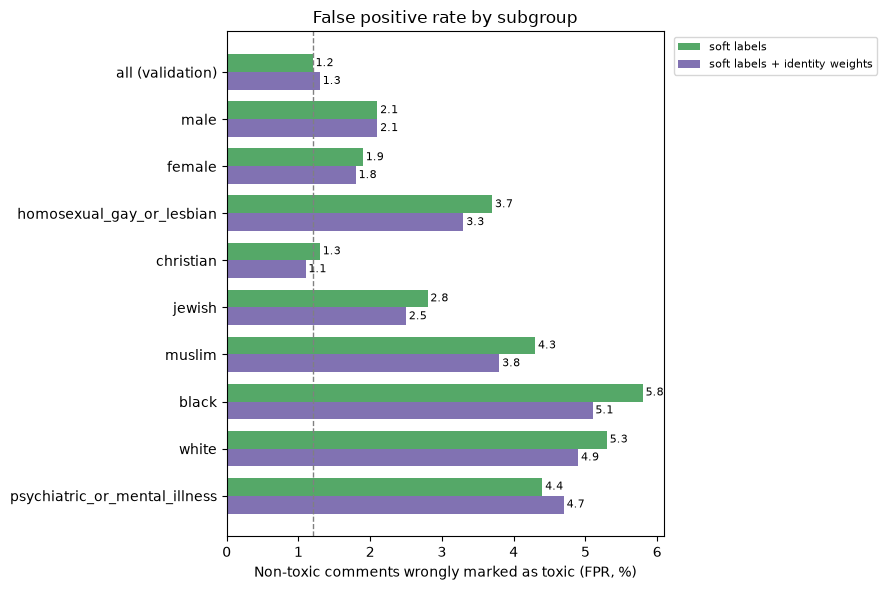

In [27]:
compare = ["soft labels", "soft labels + identity weights"]
colors = ["#55A868", "#8172B2"]

groups = list(by_group.index)
y = np.arange(len(groups))
height = 0.38

fig, ax = plt.subplots(figsize=(9, 6))
for k, (name, color) in enumerate(zip(compare, colors)):
    values = by_group[(name, "fpr")]
    bars = ax.barh(y + k * height, values, height, color=color, label=name)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], padding=2, fontsize=8)

ax.axvline(by_group.loc["all (validation)", (compare[0], "fpr")], color="gray", linestyle="--", linewidth=1)
ax.set_yticks(y + height / 2, groups)
ax.invert_yaxis()
ax.set_xlabel("Non-toxic comments wrongly marked as toxic (FPR, %)")
ax.set_title("False positive rate by subgroup")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

# 4. Probe Sentences

In [28]:
probes = pd.read_csv(PROBES_PATH)
tokenizer = AutoTokenizer.from_pretrained(f"../models/{MODELS['base lr 2e-5']}/final")
inputs = tokenizer(probes["sentence"].tolist(), padding=True, truncation=True, max_length=128, return_tensors="pt")

for name, run in MODELS.items():
    model = AutoModelForSequenceClassification.from_pretrained(f"../models/{run}/final").eval()
    with torch.no_grad():
        probs = torch.softmax(model(**inputs).logits, dim=1)[:, 1].numpy()
    probes[name] = probs.round(3)

probes = probes.rename(columns={"expected": "target"})
for category, group in probes.groupby("category", sort=False):
    print(f"\n{category}")
    display(group[["sentence", "target"] + list(MODELS)].reset_index(drop=True))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


negation with insult


...

,sentence,target,base lr 2e-5,base lr 3e-5,soft labels,soft labels + identity weights
0,Calling someone an idiot is not okay,non-toxic,0.995,0.995,0.835,0.867
1,Saying gay people are disgusting is hateful,non-toxic,0.993,0.980,0.778,0.749



profanity


,sentence,target,base lr 2e-5,base lr 3e-5,soft labels,soft labels + identity weights
0,This movie is fucking amazing,non-toxic,0.896,0.983,0.504,0.522
1,Holy shit what a great game,non-toxic,0.992,0.993,0.884,0.863



word order


,sentence,target,base lr 2e-5,base lr 3e-5,soft labels,soft labels + identity weights
0,You are an idiot and I am right,toxic,0.995,0.995,0.929,0.929
1,I am an idiot and you are right,non-toxic,0.995,0.995,0.898,0.910


In [29]:
# Number of probe sentences classified correctly by each model (threshold 0.5)
correct = {name: ((probes[name] >= 0.5) == (probes["target"] == "toxic")) for name in MODELS}
correct = pd.DataFrame(correct).assign(category=probes["category"])

hits = correct.groupby("category", sort=False).sum()
hits.insert(0, "sentences", probes.groupby("category", sort=False).size())
hits.loc["total"] = hits.sum()
hits

,sentences,base lr 2e-5,base lr 3e-5,soft labels,soft labels + identity weights
category,,,,,
negation with insult,4,2,2,2,2
negation without insult,4,3,2,4,4
identity mention,8,6,7,7,7
counter-speech,2,0,0,0,0
profanity,2,0,0,0,0
word order,2,1,1,1,1
total,22,12,12,14,14


# 5. Choice of the Best Model

We choose **soft labels + identity weights, epoch 2** , with the default threshold of 0.5.

1. **Detection of toxic comments.** Since we prioritize recall over precision, we want the model that misses the fewest toxic comments without flagging many innocent ones. 

2. **Less identity bias.** Errors on comments that mention an identity are weighted more in the loss, so the model is penalized more for them during training.

